# 05 · Seasonal scenario: power study (Phase 4, RQ3)
**The seasonal signal is imposed by simulation.** This notebook answers *"how large must a seasonal change be, and how many
samples are needed, before standard tools detect it?"*, not *"how seasonal are belly-button bacteria?"*.

Everything here follows the analysis plan `report/analysis_plan_phase4.md`, which was written and frozen **before** any power
result was computed. The first cell checks that the plan file is unchanged (SHA-256).

In [1]:
import sys, pathlib, hashlib, os, time, warnings
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from concurrent.futures import ProcessPoolExecutor
from src.config import SEED, PROCESSED, FIGURES, READS
from src.plotstyle import set_style, PALETTE
from src.power import run_point, simulate_seasonal, driver, NAMED, UNASSIGNED
set_style()

PLAN = ROOT / "report" / "analysis_plan_phase4.md"
FROZEN_SHA256 = "53a474f05a8a813d429dcb5ec30c89fe46aba5aa1f06548b65a9bf63fc49d35d"   # text above "## Amendments"
text = PLAN.read_text()
sha = hashlib.sha256(text[:text.index("## Amendments")].encode()).hexdigest()
assert sha == FROZEN_SHA256, f"analysis plan changed after freezing: {sha}"
print("frozen part of the analysis plan unchanged:", sha[:16], "...;", text.count("**Amendment"), "dated amendment(s)")

P3 = np.load(PROCESSED / "model_params.npz", allow_pickle=True)
P4 = np.load(PROCESSED / "model_params_m4.npz", allow_pickle=True)
cols = list(P3["columns"])
assert cols[UNASSIGNED] == "Unassigned" and cols[-1] == "Other" and len(cols) == 22 and list(P4["columns"]) == cols
R = 1000
A_GRID = [0, 0.1, 0.25, 0.5, 0.75, 1.0, 1.5]; N_GRID = [48, 96, 192, 288, 384]

frozen part of the analysis plan unchanged: 53a474f05a8a813d ...; 1 dated amendment(s)


## 1. The scenario
Driver `s(m) = cos(2π(m − 7)/12)`: +1 in July, −1 in January. For K randomly chosen named taxa the log-ratio to `Other` is shifted
by `A·s(m)` (signs alternate between taxa). The panels show the driver, the size of the effect against the real between-person
spread of a log-ratio, and one simulated study (illustration only, not a power result).

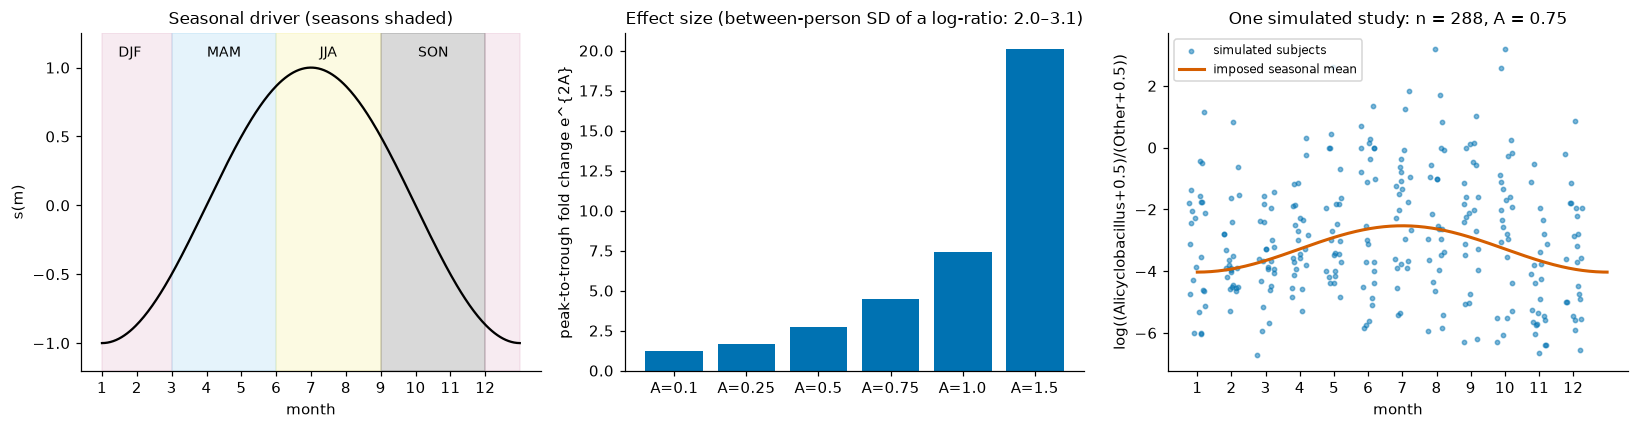

In [2]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
m = np.linspace(1, 12.99, 300)
for k, (lo, hi, lab) in enumerate([(12, 15, "DJF"), (3, 6, "MAM"), (6, 9, "JJA"), (9, 12, "SON")]):
    for a_, b_ in ([(12, 13), (1, 3)] if lab == "DJF" else [(lo, hi)]):
        ax[0].axvspan(a_, b_, color=PALETTE[k + 4], alpha=.15)
    ax[0].text((lo + hi) / 2 if lab != "DJF" else 1.8, 1.08, lab, ha="center", fontsize=9)
ax[0].plot(m, driver(m), color="k"); ax[0].set(xlabel="month", ylabel="s(m)", title="Seasonal driver (seasons shaded)", ylim=(-1.2, 1.25), xticks=range(1, 13))
A_show = np.array([0.1, 0.25, 0.5, 0.75, 1.0, 1.5]); sd = np.sqrt(np.diag(P3["Sigma"]))
ax[1].bar(range(len(A_show)), np.exp(2 * A_show), color=PALETTE[0])
ax[1].set_xticks(range(len(A_show))); ax[1].set_xticklabels([f"A={a}" for a in A_show])
ax[1].set(ylabel="peak-to-trough fold change e^{2A}", title=f"Effect size (between-person SD of a log-ratio: {sd.min():.1f}–{sd.max():.1f})")
rng = np.random.default_rng([SEED, 5, 999])
X, months, taxa = simulate_seasonal(P3["mu"], P3["Sigma"], 288, 0.75, 3, rng)
j = taxa[0]; y = np.log((X[:, j] + 0.5) / (X[:, -1] + 0.5))
ax[2].scatter(months + rng.uniform(-.25, .25, len(months)), y, s=8, alpha=.5, color=PALETTE[0], label="simulated subjects")
ax[2].plot(m, P3["mu"][j] + 0.75 * driver(m), color=PALETTE[3], lw=2, label="imposed seasonal mean")
ax[2].set(xlabel="month", ylabel=f"log(({cols[j].split(';')[-1][:18]}+0.5)/(Other+0.5))", title="One simulated study: n = 288, A = 0.75", xticks=range(1, 13)); ax[2].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIGURES / "power_schematic.png"); plt.show()

## 2. Grid (exactly as in the plan) and the run

In [3]:
rows = []
def add(scenario, sim, n, A, K=3, depth=1000, od=1.0, shuffle=False):
    rows.append(dict(scenario=scenario, simulator=sim, n=n, A=A, K=K, depth=depth, od=od, shuffle=shuffle))
for n in N_GRID:
    for A in A_GRID:
        add("main", "M3", n, A); add("M4", "M4", n, A)
for n in [96, 288]:
    for A in A_GRID:
        add("K=1", "M3", n, A, K=1); add("K=5", "M3", n, A, K=5); add("depth 10000", "M3", n, A, depth=10000)
        add("Sigma x0.5", "M3", n, A, od=0.5); add("Sigma x2", "M3", n, A, od=2.0)
for n in N_GRID:
    add("negative control", "M3", n, 1.0, shuffle=True)
grid = pd.DataFrame(rows); grid.index.name = "point_id"
assert len(grid) == 145
grid.to_csv(PROCESSED / "power_grid.csv")
grid.groupby("scenario").size()

scenario
K=1                 14
K=5                 14
M4                  35
Sigma x0.5          14
Sigma x2            14
depth 10000         14
main                35
negative control     5
dtype: int64

In [4]:
def spec(pid, g):
    p = P4 if g.simulator == "M4" else P3
    return dict(point_id=int(pid), seed=SEED, R=R, mu=p["mu"], Sigma=p["Sigma"], pi=(p["pi"] if g.simulator == "M4" else None),
                n=int(g.n), A=float(g.A), K=int(g.K), depth=int(g.depth), od=float(g.od), shuffle=bool(g.shuffle))
specs = sorted([spec(pid, g) for pid, g in grid.iterrows()], key=lambda s: -s["n"])   # largest first for load balance
t0 = time.time()
with ProcessPoolExecutor(max_workers=os.cpu_count()) as ex:
    raw = pd.DataFrame([r for out in ex.map(run_point, specs) for r in out])
print(f"{len(raw)} replicates in {time.time() - t0:.0f} s")
raw = raw.sort_values(["point_id", "rep"]).reset_index(drop=True)
raw.to_csv(PROCESSED / "power_raw.csv", index=False)

145000 replicates in 228 s


## 3. Summaries
* rejection rate of each test with a 95 % **Wilson** interval (better than ±1.96·SE near 0 and 1);
* Monte Carlo standard error √(p(1−p)/R);
* cosinor: sensitivity = mean share of the K affected taxa detected; empirical FDR = mean share of false rejections among
  rejections, over replicates with at least one rejection (as defined in the plan: the *positive* FDR);
  **amendment 1:** also the standard FDR = mean of false/max(rejections, 1) over all replicates, which is what BH controls.

In [5]:
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n; c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h
TESTS = {"PERMANOVA Aitchison": "p_permanova_ait", "PERMANOVA Bray-Curtis": "p_permanova_bc", "cosinor CLR + BH": "cosinor_any"}
raw["PERMANOVA Aitchison"] = raw["p_permanova_ait"] <= 0.05
raw["PERMANOVA Bray-Curtis"] = raw["p_permanova_bc"] <= 0.05
raw["cosinor CLR + BH"] = raw["cosinor_any"]
raw = raw.join(grid[["K"]], on="point_id")
raw["tpr"] = raw["tp"] / raw["K"]
raw["fdp"] = np.where(raw["n_rej"] > 0, raw["fp"] / raw["n_rej"].clip(lower=1), np.nan)   # pre-specified (positive FDR)
raw["fdp0"] = raw["fp"] / raw["n_rej"].clip(lower=1)                                      # amendment 1: 0 if no rejection
agg = raw.groupby("point_id").agg(**{t: (t, "sum") for t in TESTS}, tpr=("tpr", "mean"), fdr=("fdp", "mean"), fdr_bh=("fdp0", "mean"))
summ = grid.join(agg)
for t in TESTS:
    k = summ[t]; summ[t] = k / R; lo, hi = wilson(k, R); summ[t + " lo"], summ[t + " hi"] = lo, hi
summ.to_csv(PROCESSED / "power_summary.csv")

## 4. Validity first: type I error at A = 0 and the negative control

In [6]:
band = (0.05 - 2 * np.sqrt(.05 * .95 / R), 0.05 + 2 * np.sqrt(.05 * .95 / R))
t1 = summ[(summ.A == 0) & ~summ.shuffle].set_index(["scenario", "n"])[list(TESTS)]
t1_ok = t1.apply(lambda c: c.between(*band))
print(f"acceptance band (0.05 ± 2 MCSE, R={R}): {band[0]:.3f}–{band[1]:.3f}")
print("type I error rates outside the band:", int((~t1_ok).values.sum()), "of", t1_ok.size)
t1.to_csv(PROCESSED / "power_type1.csv"); t1.round(3)

acceptance band (0.05 ± 2 MCSE, R=1000): 0.036–0.064
type I error rates outside the band: 2 of 60


,,PERMANOVA Aitchison,PERMANOVA Bray-Curtis,cosinor CLR + BH
scenario,n,,,
main,48,0.048,0.042,0.044
M4,48,0.059,0.043,0.046
main,96,0.051,0.050,0.057
M4,96,0.049,0.063,0.040
main,192,0.045,0.052,0.046
M4,192,0.052,0.043,0.052
main,288,0.040,0.053,0.041
M4,288,0.035,0.044,0.044
main,384,0.049,0.039,0.050


In [7]:
neg = summ[summ.shuffle].set_index("n")[list(TESTS)]
print("negative control (A = 1.0, month labels shuffled) — should be ≈ 0.05; outside band:", int((~neg.apply(lambda c: c.between(*band))).values.sum()), "of", neg.size)
neg.round(3)

negative control (A = 1.0, month labels shuffled) — should be ≈ 0.05; outside band: 4 of 15


,PERMANOVA Aitchison,PERMANOVA Bray-Curtis,cosinor CLR + BH
n,,,
48,0.046,0.044,0.044
96,0.039,0.047,0.033
192,0.035,0.054,0.032
288,0.042,0.054,0.050
384,0.052,0.036,0.049


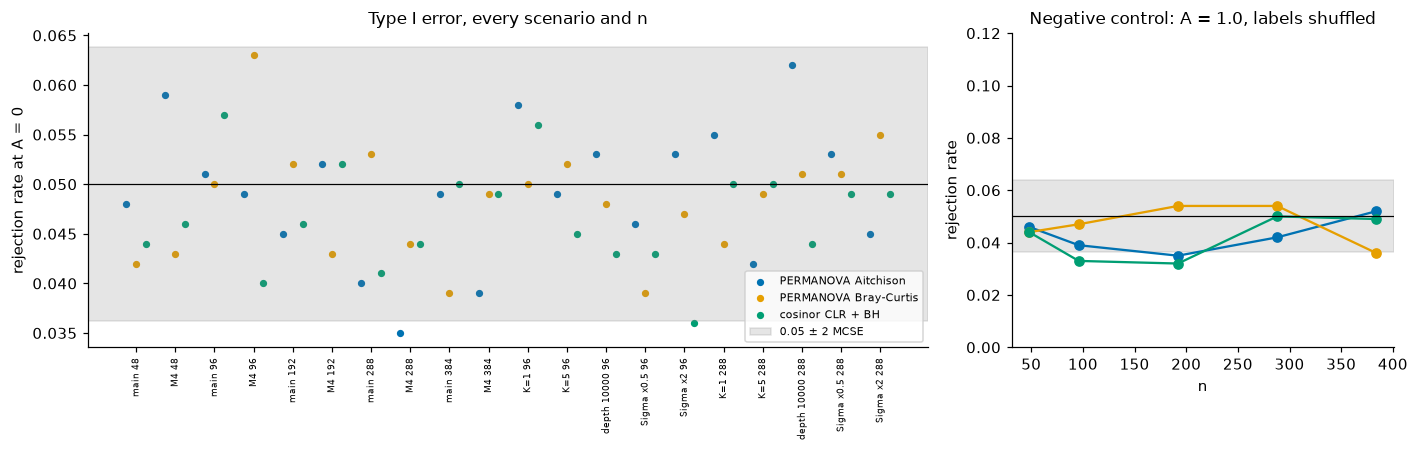

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [2.2, 1]})
lab = [f"{s}\nn={n}" if s == "main" else f"{s}, n={n}" for s, n in t1.index]
xs = np.arange(len(t1))
for k, t in enumerate(TESTS):
    ax[0].scatter(xs + (k - 1) * 0.25, t1[t], s=14, color=PALETTE[k], label=t)
ax[0].axhspan(*band, color="grey", alpha=.2, label="0.05 ± 2 MCSE"); ax[0].axhline(0.05, color="k", lw=.8)
ax[0].set_xticks(xs); ax[0].set_xticklabels([f"{s} {n}" for s, n in t1.index], rotation=90, fontsize=6)
ax[0].set(ylabel="rejection rate at A = 0", title="Type I error, every scenario and n"); ax[0].legend(fontsize=7)
for k, t in enumerate(TESTS):
    ax[1].plot(neg.index, neg[t], "o-", color=PALETTE[k], label=t)
ax[1].axhspan(*band, color="grey", alpha=.2); ax[1].axhline(0.05, color="k", lw=.8)
ax[1].set(xlabel="n", ylabel="rejection rate", title="Negative control: A = 1.0, labels shuffled", ylim=(0, .12))
fig.tight_layout(); fig.savefig(FIGURES / "power_type1.png"); plt.show()

## 5. Main scenario (M3, K = 3, depth 1000): power curves, power vs n, heatmap

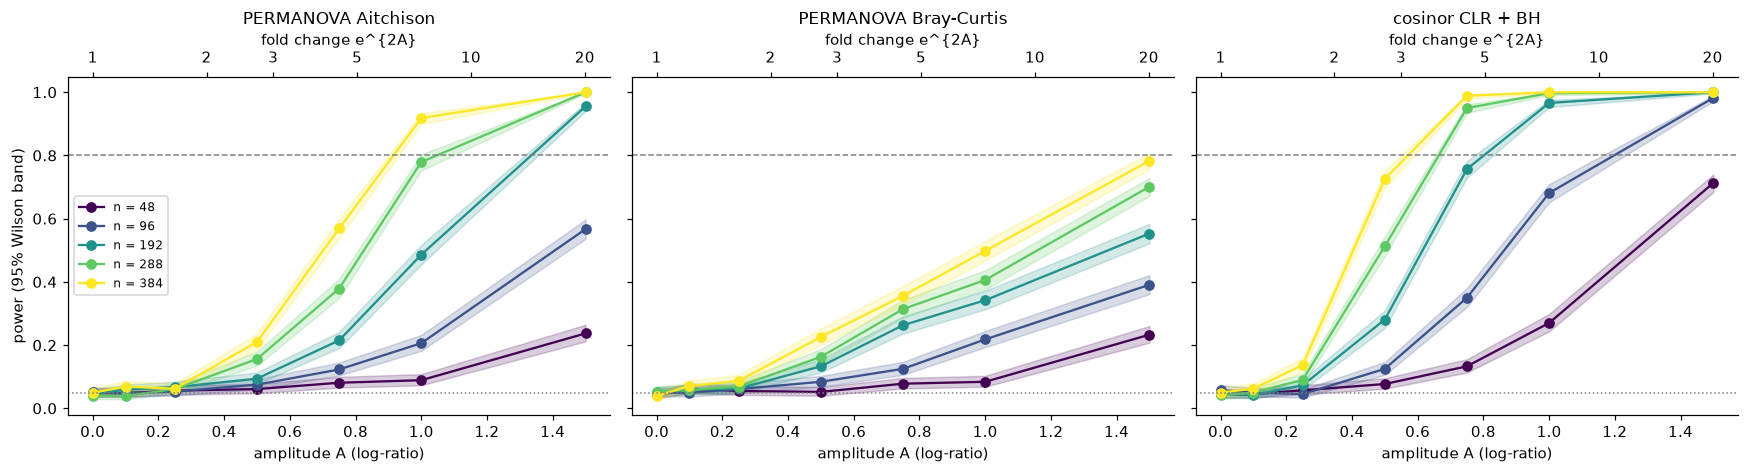

In [9]:
main = summ[summ.scenario == "main"]
cmap = plt.get_cmap("viridis")
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4), sharey=True)
for a, t in zip(ax, TESTS):
    for k, n in enumerate(N_GRID):
        d = main[main.n == n].sort_values("A"); c = cmap(k / (len(N_GRID) - 1))
        a.plot(d.A, d[t], "o-", color=c, label=f"n = {n}"); a.fill_between(d.A, d[t + " lo"], d[t + " hi"], color=c, alpha=.2)
    a.axhline(0.8, color="grey", ls="--", lw=1); a.axhline(0.05, color="grey", ls=":", lw=1)
    a.set(xlabel="amplitude A (log-ratio)", title=t)
    sec = a.secondary_xaxis("top", functions=(lambda x: np.exp(2 * x), lambda f: np.log(np.clip(f, 1e-9, None)) / 2))
    sec.set_xticks([1, 2, 3, 5, 10, 20]); sec.set_xlabel("fold change e^{2A}")
ax[0].set_ylabel("power (95% Wilson band)"); ax[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIGURES / "power_curves_main.png"); plt.show()

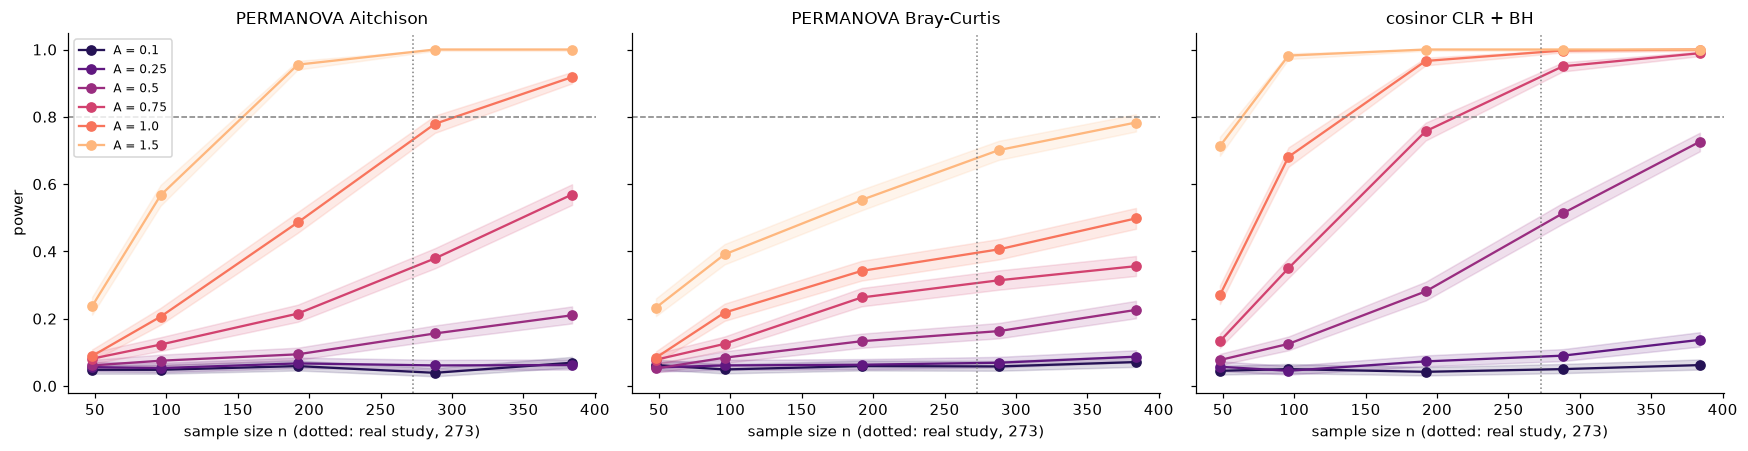

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for a, t in zip(ax, TESTS):
    for k, A in enumerate([x for x in A_GRID if x > 0]):
        d = main[main.A == A].sort_values("n"); c = plt.get_cmap("magma")(0.15 + 0.7 * k / 5)
        a.plot(d.n, d[t], "o-", color=c, label=f"A = {A}"); a.fill_between(d.n, d[t + " lo"], d[t + " hi"], color=c, alpha=.15)
    a.axhline(0.8, color="grey", ls="--", lw=1); a.axvline(273, color="grey", ls=":", lw=1)
    a.set(xlabel="sample size n (dotted: real study, 273)", title=t)
ax[0].set_ylabel("power"); ax[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIGURES / "power_vs_n.png"); plt.show()

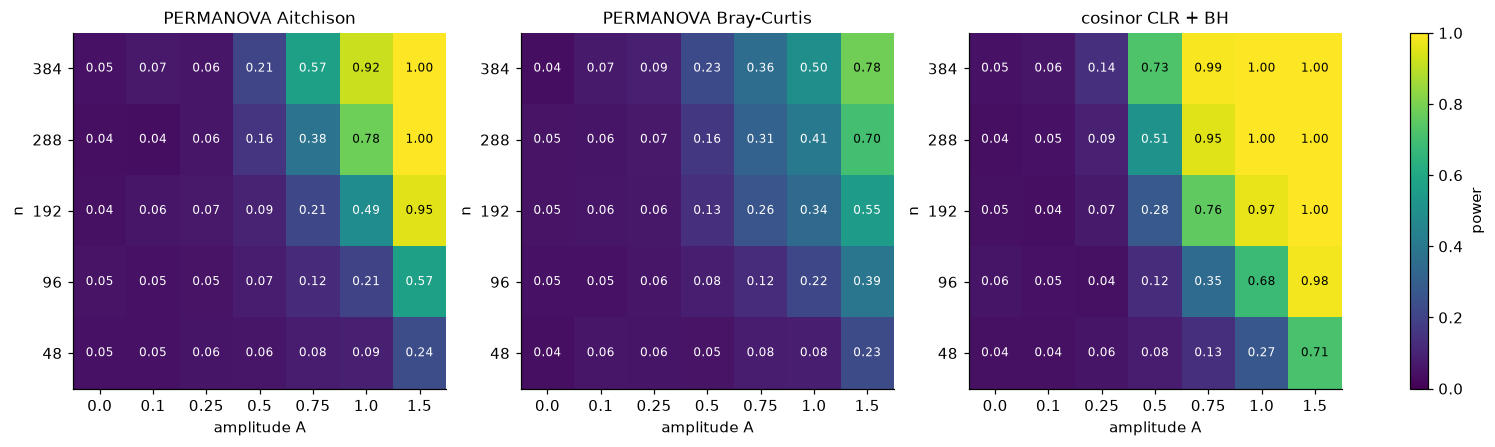

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for a, t in zip(ax, TESTS):
    H = main.pivot(index="n", columns="A", values=t).loc[N_GRID[::-1]]
    im = a.imshow(H.values, cmap="viridis", vmin=0, vmax=1, aspect="auto")
    for i in range(H.shape[0]):
        for j in range(H.shape[1]):
            a.text(j, i, f"{H.values[i, j]:.2f}", ha="center", va="center", fontsize=8, color="w" if H.values[i, j] < .6 else "k")
    a.set_xticks(range(H.shape[1])); a.set_xticklabels(H.columns); a.set_yticks(range(H.shape[0])); a.set_yticklabels(H.index)
    a.set(xlabel="amplitude A", ylabel="n", title=t)
plt.colorbar(im, ax=ax, fraction=.02, label="power"); fig.savefig(FIGURES / "power_heatmap.png", bbox_inches="tight"); plt.show()

## 6. Minimum detectable effect (power ≥ 0.80)
Linear interpolation of power between neighbouring grid values of A; "> 1.5" if 0.80 is never reached on the grid.

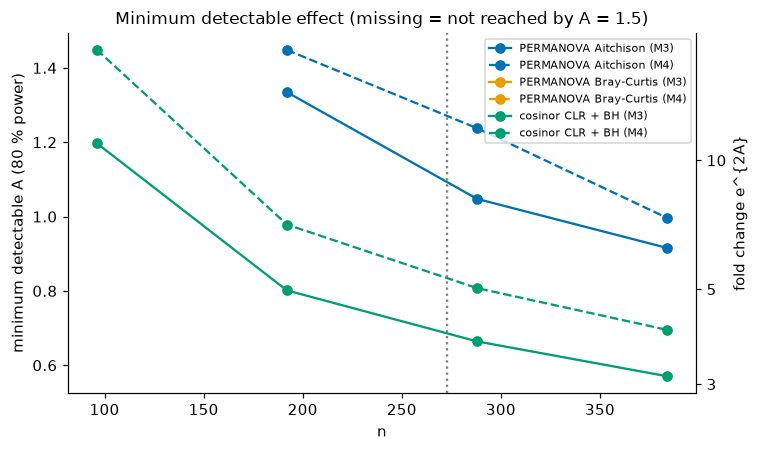

PERMANOVA Aitchison  PERMANOVA Bray-Curtis  cosinor CLR + BH
scenario n                                                                
main     48                   inf                    inf               inf
         96                   inf                    inf              1.20
         192                 1.33                    inf              0.80
         288                 1.05                    inf              0.66
         384                 0.92                    inf              0.57
M4       48                   inf                    inf               inf
         96                   inf                    inf              1.45
         192                 1.45                    inf              0.98
         288                 1.24                    inf              0.81
         384                 1.00                    inf              0.70

In [12]:
def mde(d, t, target=0.8):
    d = d.sort_values("A"); a, p = d.A.values, d[t].values
    k = np.argmax(p >= target)
    if p[k] < target: return np.inf
    if k == 0: return a[0]
    return a[k - 1] + (target - p[k - 1]) * (a[k] - a[k - 1]) / (p[k] - p[k - 1])
mde_rows = []
for sc in ["main", "M4"]:
    for n in N_GRID:
        d = summ[(summ.scenario == sc) & (summ.n == n)]
        mde_rows.append({"scenario": sc, "n": n, **{t: mde(d, t) for t in TESTS}})
mde_tab = pd.DataFrame(mde_rows).set_index(["scenario", "n"]); mde_tab.to_csv(PROCESSED / "power_mde.csv")
fig, ax = plt.subplots(figsize=(7, 4.2))
for k, t in enumerate(TESTS):
    for sc, ls in [("main", "-"), ("M4", "--")]:
        v = mde_tab.loc[sc][t].replace(np.inf, np.nan)
        ax.plot(N_GRID, v, ls, marker="o", color=PALETTE[k], label=f"{t} ({'M3' if sc == 'main' else 'M4'})")
ax.axvline(273, color="grey", ls=":"); ax.set(xlabel="n", ylabel="minimum detectable A (80 % power)", title="Minimum detectable effect (missing = not reached by A = 1.5)")
ax2 = ax.secondary_yaxis("right", functions=(lambda x: np.exp(2 * x), lambda f: np.log(np.clip(f, 1e-9, None)) / 2)); ax2.set_yticks([2, 3, 5, 10, 20]); ax2.set_ylabel("fold change e^{2A}")
ax.legend(fontsize=7); fig.tight_layout(); fig.savefig(FIGURES / "power_mde.png"); plt.show()
mde_tab.round(2)

## 7. Cosinor per taxon: sensitivity and FDR (main scenario)
Middle panel: the pre-specified quantity (positive FDR, only replicates with ≥ 1 rejection). It is near 1 at small A by construction:
when there is almost no signal, the few studies that reject do so by chance. Right panel (amendment 1): the standard FDR that BH
controls. Values above q at large A come from closure: shifting K taxa moves the CLR of every taxon a little.

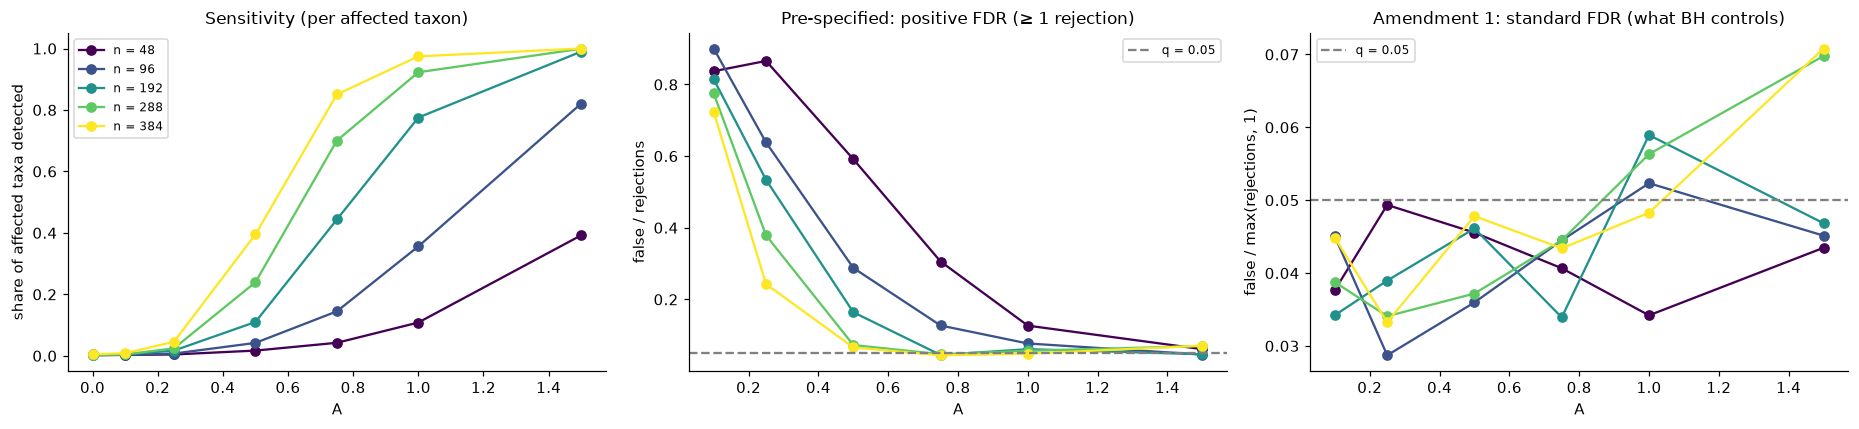

A                                  0.00   0.10   0.25   0.50   0.75   1.00  \
                             n                                               
positive FDR (pre-specified) 48   0.940  0.837  0.866  0.592  0.306  0.127   
                             96   0.852  0.900  0.638  0.288  0.127  0.077   
                             192  0.861  0.815  0.534  0.164  0.045  0.061   
                             288  0.902  0.775  0.379  0.072  0.047  0.056   
                             384  0.795  0.723  0.243  0.066  0.044  0.048   
standard FDR (amendment 1)   48   0.041  0.038  0.049  0.046  0.041  0.034   
                             96   0.049  0.045  0.029  0.036  0.044  0.052   
                             192  0.040  0.034  0.039  0.046  0.034  0.059   
                             288  0.037  0.039  0.034  0.037  0.044  0.056   
                             384  0.040  0.045  0.033  0.048  0.043  0.048   

A                                  1.50  
                             n           
positive FDR (pre-specified) 48   0.061  
                             96   0.046  
                             192  0.047  
                             288  0.070  
                             384  0.071  
standard FDR (amendment 1)   48   0.043  
                             96   0.045  
                             192  0.047  
                             288  0.070  
                             384  0.071

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for k, n in enumerate(N_GRID):
    d = main[main.n == n].sort_values("A"); c = cmap(k / (len(N_GRID) - 1)); pos = d.A > 0
    ax[0].plot(d.A, d.tpr, "o-", color=c, label=f"n = {n}")
    ax[1].plot(d.A[pos], d.fdr[pos], "o-", color=c); ax[2].plot(d.A[pos], d.fdr_bh[pos], "o-", color=c)
ax[0].set(xlabel="A", ylabel="share of affected taxa detected", title="Sensitivity (per affected taxon)"); ax[0].legend(fontsize=8)
for a in ax[1:]: a.axhline(0.05, color="grey", ls="--", label="q = 0.05"); a.legend(fontsize=8); a.set_xlabel("A")
ax[1].set(ylabel="false / rejections", title="Pre-specified: positive FDR (≥ 1 rejection)")
ax[2].set(ylabel="false / max(rejections, 1)", title="Amendment 1: standard FDR (what BH controls)")
fig.tight_layout(); fig.savefig(FIGURES / "power_cosinor_fdr.png"); plt.show()
pd.concat({"positive FDR (pre-specified)": main.pivot(index="n", columns="A", values="fdr"),
           "standard FDR (amendment 1)": main.pivot(index="n", columns="A", values="fdr_bh")}).round(3)

## 8. Sensitivity analyses (n = 96 dashed, n = 288 solid)

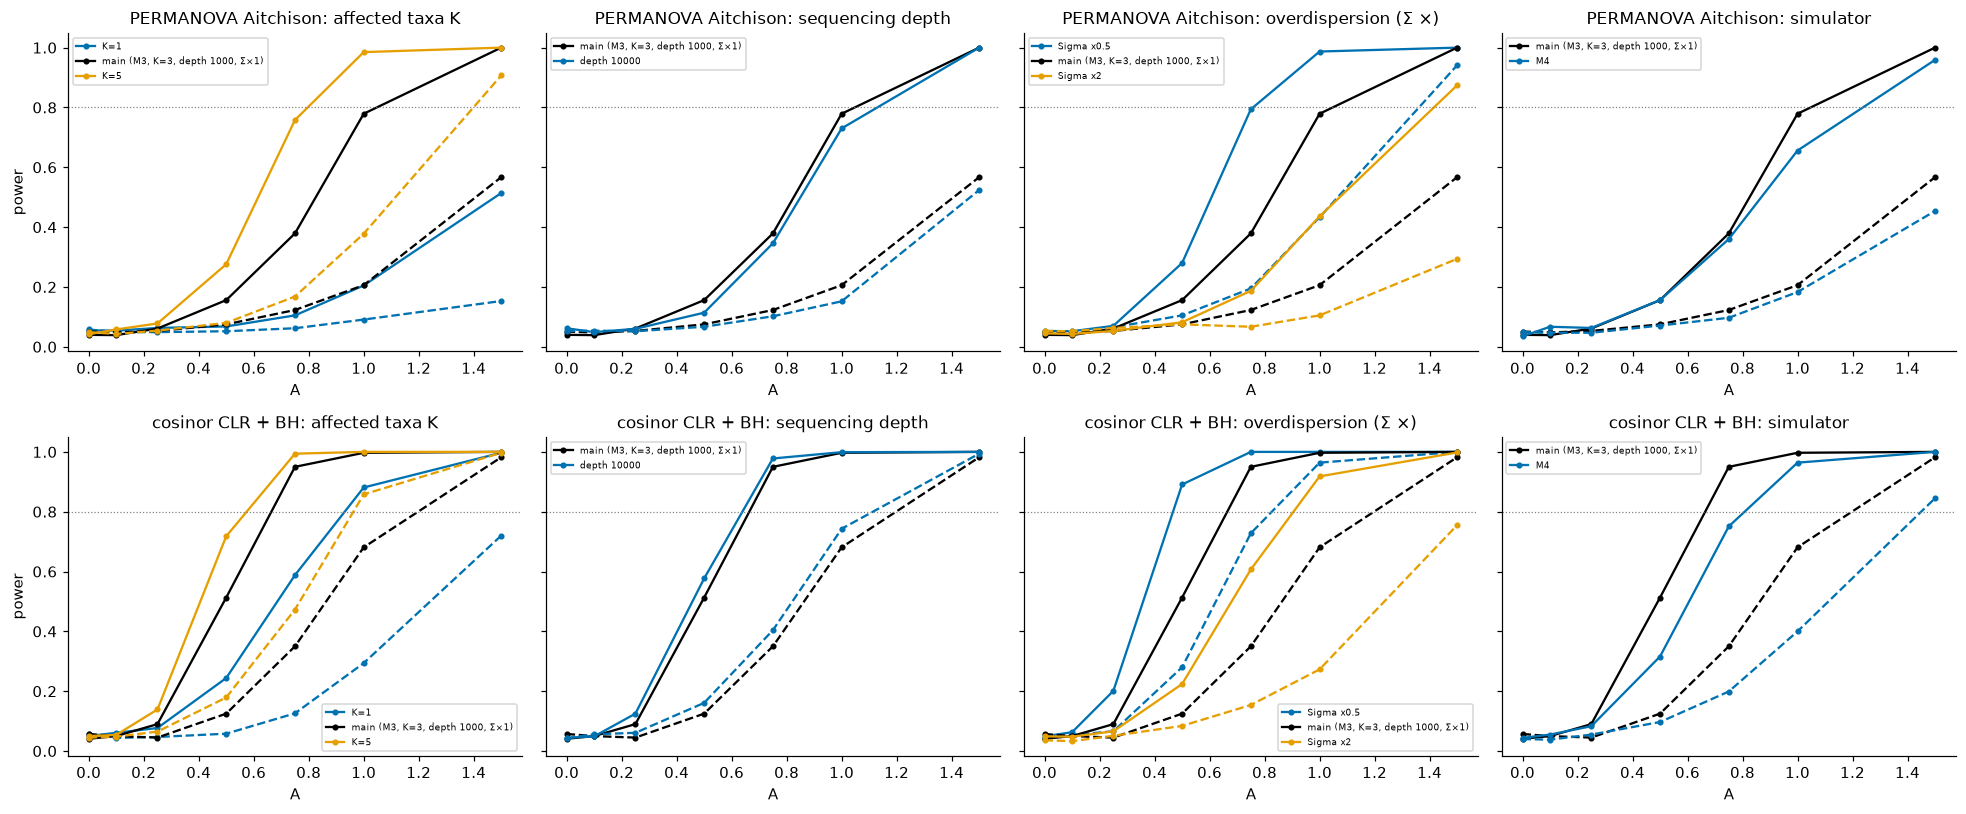

PERMANOVA Aitchison       cosinor CLR + BH      
A                               0.5   1.0              0.5   1.0
scenario    n                                                   
K=1         96                 0.05  0.09             0.06  0.29
            288                0.07  0.20             0.24  0.88
K=5         96                 0.08  0.38             0.18  0.86
            288                0.28  0.98             0.72  1.00
M4          96                 0.07  0.18             0.10  0.40
            288                0.16  0.66             0.32  0.96
Sigma x0.5  96                 0.10  0.43             0.28  0.96
            288                0.28  0.99             0.89  1.00
Sigma x2    96                 0.08  0.10             0.08  0.27
            288                0.08  0.44             0.22  0.92
depth 10000 96                 0.07  0.15             0.16  0.74
            288                0.11  0.73             0.58  1.00
main        96                 0.08  0.21             0.12  0.68
            288                0.16  0.78             0.51  1.00

In [14]:
groups = {"affected taxa K": ["K=1", "main", "K=5"], "sequencing depth": ["main", "depth 10000"],
          "overdispersion (Σ ×)": ["Sigma x0.5", "main", "Sigma x2"], "simulator": ["main", "M4"]}
names = {"main": "main (M3, K=3, depth 1000, Σ×1)"}
prim = ["PERMANOVA Aitchison", "cosinor CLR + BH"]
fig, ax = plt.subplots(len(prim), len(groups), figsize=(18, 7.5), sharey=True)
for c_, (gname, scs) in enumerate(groups.items()):
    for r_, t in enumerate(prim):
        for k, sc in enumerate(scs):
            for n, ls in [(96, "--"), (288, "-")]:
                d = summ[(summ.scenario == sc) & (summ.n == n)].sort_values("A")
                col = "k" if sc == "main" else PALETTE[[s_ for s_ in scs if s_ != "main"].index(sc)]
                ax[r_, c_].plot(d.A, d[t], ls, marker="o", ms=3, color=col, label=f"{names.get(sc, sc)}" if n == 288 else None)
        ax[r_, c_].axhline(0.8, color="grey", lw=.8, ls=":")
        ax[r_, c_].set(title=f"{t}: {gname}", xlabel="A"); ax[r_, c_].legend(fontsize=6)
    ax[0, 0].set_ylabel("power"); ax[1, 0].set_ylabel("power")
fig.tight_layout(); fig.savefig(FIGURES / "power_sensitivity.png"); plt.show()
sens = summ[summ.n.isin([96, 288]) & ~summ.shuffle & (summ.A.isin([0.5, 1.0]))].pivot_table(index=["scenario", "n"], columns="A", values=prim)
sens.round(2)

## 9. Key numbers (used by the report)

In [15]:
key = {}
for t in TESTS:
    for n in [96, 288]:
        key[f"MDE {t} n={n} (M3)"] = mde_tab.loc[("main", n), t]
        key[f"MDE {t} n={n} (M4)"] = mde_tab.loc[("M4", n), t]
key["type I outside band"] = int((~t1_ok).values.sum()); key["type I max"] = float(t1.values.max()); key["type I min"] = float(t1.values.min())
key["negative control max"] = float(neg.values.max()); key["negative control min"] = float(neg.values.min())
key["max standard FDR main (A>0)"] = float(main.loc[main.A > 0, "fdr_bh"].max())
pd.Series(key).to_csv(PROCESSED / "power_key_numbers.csv", header=["value"]); pd.Series(key).round(3)

MDE PERMANOVA Aitchison n=96 (M3)         inf
MDE PERMANOVA Aitchison n=96 (M4)         inf
MDE PERMANOVA Aitchison n=288 (M3)      1.048
MDE PERMANOVA Aitchison n=288 (M4)      1.238
MDE PERMANOVA Bray-Curtis n=96 (M3)       inf
MDE PERMANOVA Bray-Curtis n=96 (M4)       inf
MDE PERMANOVA Bray-Curtis n=288 (M3)      inf
MDE PERMANOVA Bray-Curtis n=288 (M4)      inf
MDE cosinor CLR + BH n=96 (M3)          1.198
MDE cosinor CLR + BH n=96 (M4)          1.449
MDE cosinor CLR + BH n=288 (M3)         0.664
MDE cosinor CLR + BH n=288 (M4)         0.808
type I outside band                     2.000
type I max                              0.063
type I min                              0.035
negative control max                    0.054
negative control min                    0.032
max standard FDR main (A>0)             0.071
dtype: float64